In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

📌 IQR Method
Q1=2372.50, Q3=2512.50, IQR=140.00, Lower Bound=2162.50, Upper Bound=2722.50
Outliers Detected: [ 3000 10000]


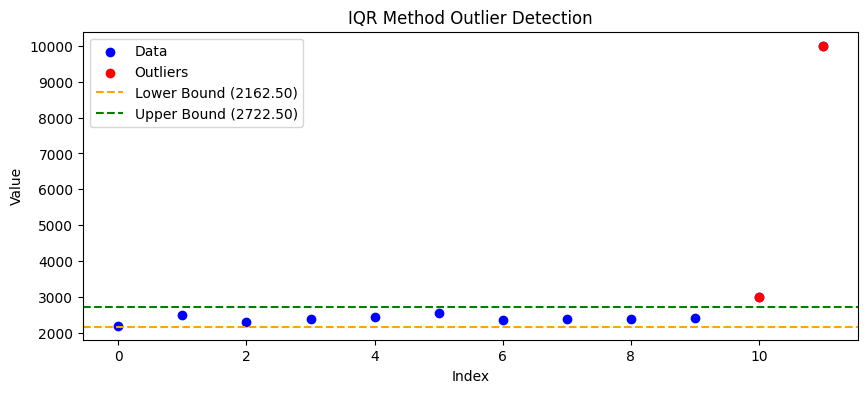


📌 Z-Score Method (Default Threshold=3)
Mean=3079.17, Std Dev=2095.10
Z-Scores: [-0.41963087 -0.27643929 -0.37190035 -0.32416982 -0.30030456 -0.25257403
 -0.34803508 -0.32416982 -0.33371593 -0.31462372 -0.03778667  3.30335013]
Outliers Detected: [10000]


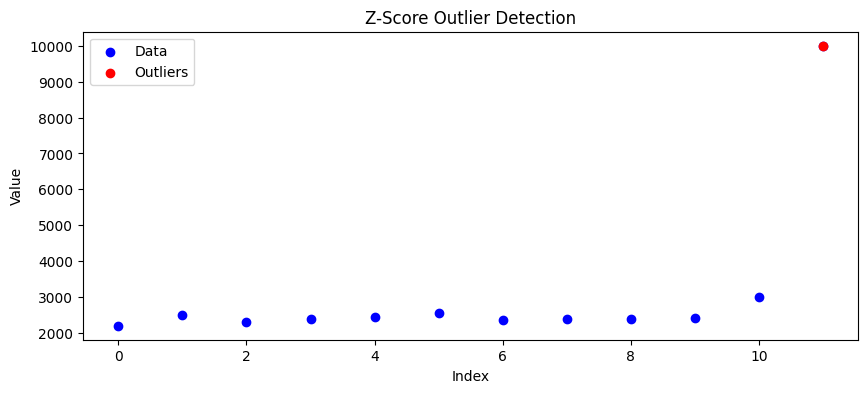


📌 3-Sigma Rule
Lower Bound=-3206.12, Upper Bound=9364.45
Outliers Detected: [10000]


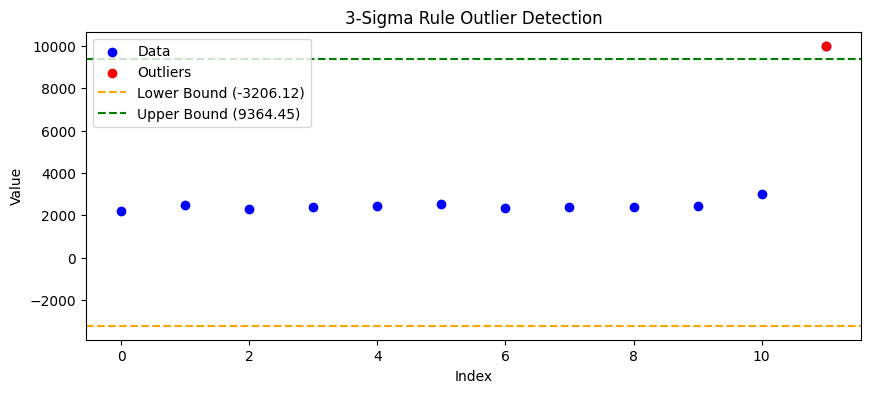


📌 Modified Z-Score Method
Median=2410.00, MAD=75.00
Modified Z-Scores: [-1.8886      0.8094     -0.98926667 -0.08993333  0.35973333  1.25906667
 -0.5396     -0.08993333 -0.2698      0.08993333  5.30606667 68.2594    ]
Outliers Detected: [ 3000 10000]


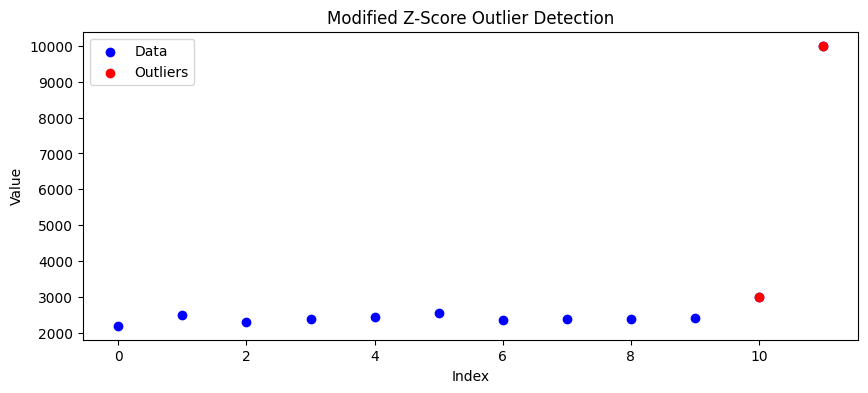

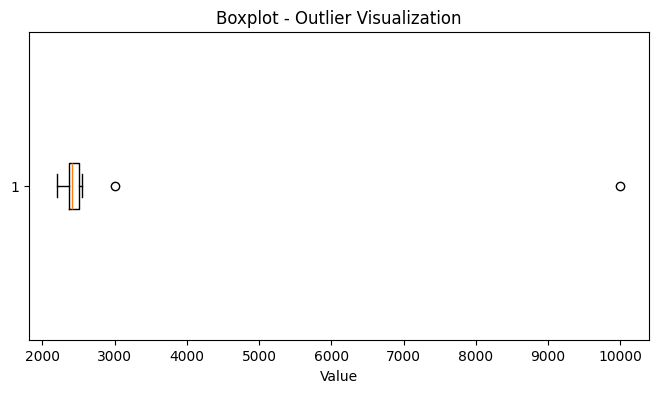

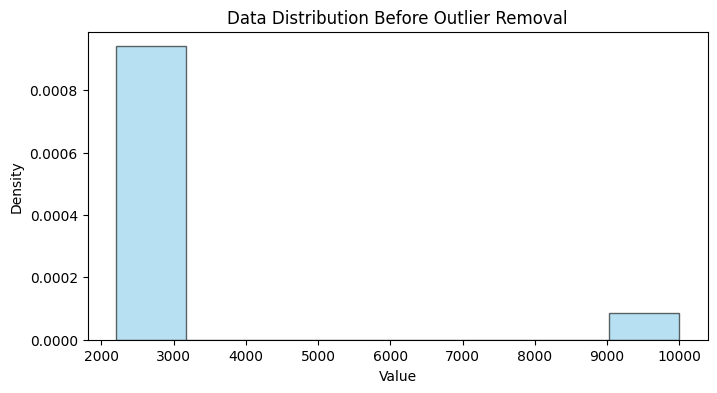


✅ Cleaned Data (IQR): [2200 2500 2300 2400 2450 2550 2350 2400 2380 2420]


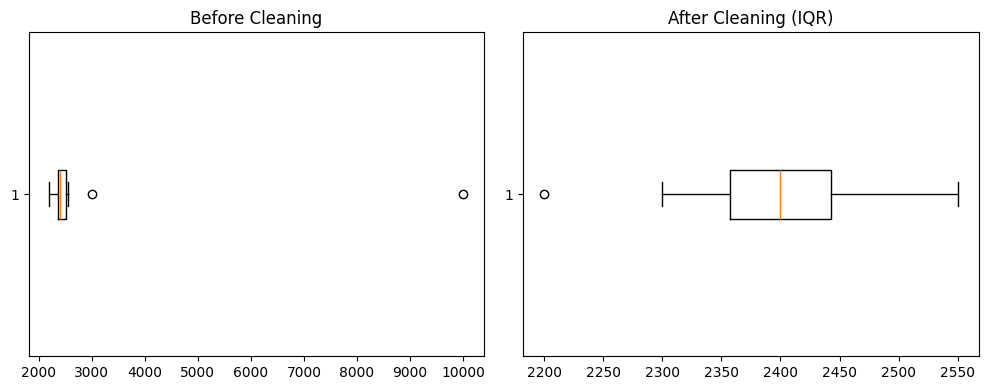

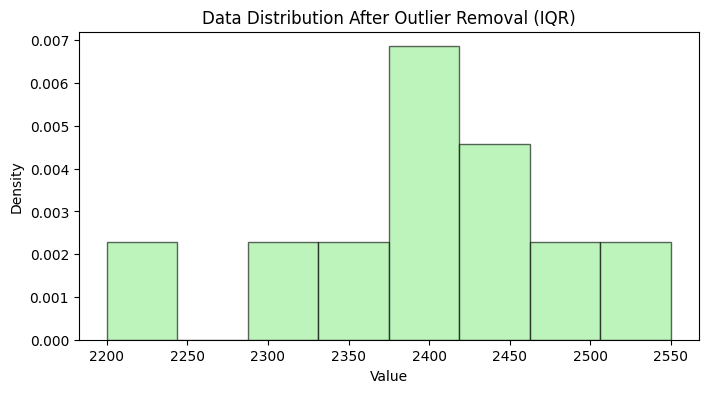

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1️⃣ Dataset
data = np.array([2200, 2500, 2300, 2400, 2450, 2550, 2350, 2400, 2380, 2420, 3000, 10000])

# -----------------------------
# Helper function to visualize data
def plot_data(data, title, outliers=None, lb=None, ub=None):
    plt.figure(figsize=(10, 4))
    plt.scatter(range(len(data)), data, label="Data", color="blue")
    
    if outliers is not None and len(outliers) > 0:
        plt.scatter([i for i, x in enumerate(data) if x in outliers],
                    outliers, color="red", label="Outliers", zorder=5)
    if lb is not None and ub is not None:
        plt.axhline(lb, color='orange', linestyle="--", label=f"Lower Bound ({lb:.2f})")
        plt.axhline(ub, color='green', linestyle="--", label=f"Upper Bound ({ub:.2f})")
    
    plt.title(title)
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.legend()
    plt.show()

# -----------------------------
# 2️⃣ IQR Method (Robust)
def detect_outliers_iqr(data):
    """
    ✅ Use when:
    - Data may be skewed or not normally distributed.
    - You want a robust method that ignores extreme mean shifts.
    """
    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)
    IQR = Q3 - Q1
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR
    outliers = data[(data < lb) | (data > ub)]
    return outliers, lb, ub, Q1, Q3, IQR

iqr_outliers, lb_iqr, ub_iqr, Q1, Q3, IQR = detect_outliers_iqr(data)
print("📌 IQR Method")
print(f"Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, Lower Bound={lb_iqr:.2f}, Upper Bound={ub_iqr:.2f}")
print("Outliers Detected:", iqr_outliers)
plot_data(data, "IQR Method Outlier Detection", iqr_outliers, lb_iqr, ub_iqr)

# -----------------------------
# 3️⃣ Z-Score Method (Mean & Std Dev)
def detect_outliers_zscore(data, threshold=3):
    """
    ✅ Use when:
    - Data follows a normal distribution.
    - You are okay with mean being influenced by outliers.
    """
    mean = np.mean(data)
    std = np.std(data)
    z_scores = (data - mean) / std
    outliers = data[np.abs(z_scores) > threshold]
    return outliers, z_scores, mean, std

z_outliers, z_scores, mean_z, std_z = detect_outliers_zscore(data)
print("\n📌 Z-Score Method (Default Threshold=3)")
print(f"Mean={mean_z:.2f}, Std Dev={std_z:.2f}")
print("Z-Scores:", z_scores)
print("Outliers Detected:", z_outliers)
plot_data(data, "Z-Score Outlier Detection", z_outliers)

# -----------------------------
# 4️⃣ 3-Sigma Rule (Simpler Z-Score)
def detect_outliers_3sigma(data):
    """
    ✅ Use when:
    - You want a simple rule: keep data within mean ± 3*std.
    - Works best on Gaussian (normal) distributions.
    """
    mean = np.mean(data)
    std = np.std(data)
    lb = mean - 3 * std
    ub = mean + 3 * std
    outliers = data[(data < lb) | (data > ub)]
    return outliers, lb, ub

sigma_outliers, lb_sigma, ub_sigma = detect_outliers_3sigma(data)
print("\n📌 3-Sigma Rule")
print(f"Lower Bound={lb_sigma:.2f}, Upper Bound={ub_sigma:.2f}")
print("Outliers Detected:", sigma_outliers)
plot_data(data, "3-Sigma Rule Outlier Detection", sigma_outliers, lb_sigma, ub_sigma)

# -----------------------------
# 5️⃣ Modified Z-Score (Robust for Small Samples)
def detect_outliers_modified_z(data, threshold=3.5):
    """
    ✅ Use when:
    - Dataset is small.
    - You want median-based robust detection (less sensitive to outliers).
    """
    median = np.median(data)
    mad = np.median(np.abs(data - median))
    modified_z_scores = 0.6745 * (data - median) / mad
    outliers = data[np.abs(modified_z_scores) > threshold]
    return outliers, modified_z_scores, median, mad

mz_outliers, mz_scores, med, mad = detect_outliers_modified_z(data)
print("\n📌 Modified Z-Score Method")
print(f"Median={med:.2f}, MAD={mad:.2f}")
print("Modified Z-Scores:", mz_scores)
print("Outliers Detected:", mz_outliers)
plot_data(data, "Modified Z-Score Outlier Detection", mz_outliers)

# -----------------------------
# 6️⃣ Boxplot Visualization
plt.figure(figsize=(8, 4))
plt.boxplot(data, vert=False)
plt.title("Boxplot - Outlier Visualization")
plt.xlabel("Value")
plt.show()

# -----------------------------
# 7️⃣ Histogram + KDE before cleaning
plt.figure(figsize=(8, 4))
plt.hist(data, bins=8, density=True, alpha=0.6, color="skyblue", edgecolor="black")
plt.title("Data Distribution Before Outlier Removal")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

# -----------------------------
# 8️⃣ Remove Outliers (Using IQR)
cleaned_data = data[(data >= lb_iqr) & (data <= ub_iqr)]
print("\n✅ Cleaned Data (IQR):", cleaned_data)

# Compare boxplots before and after cleaning
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.boxplot(data, vert=False)
plt.title("Before Cleaning")

plt.subplot(1, 2, 2)
plt.boxplot(cleaned_data, vert=False)
plt.title("After Cleaning (IQR)")

plt.tight_layout()
plt.show()

# Histogram after cleaning
plt.figure(figsize=(8, 4))
plt.hist(cleaned_data, bins=8, density=True, alpha=0.6, color="lightgreen", edgecolor="black")
plt.title("Data Distribution After Outlier Removal (IQR)")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()


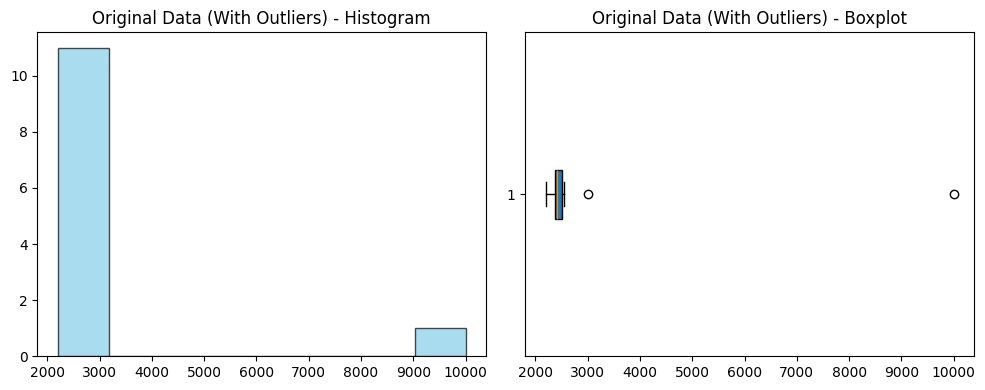

📌 IQR Outliers: [ 3000 10000]
📌 Z-Score Outliers: [10000]
📌 Modified Z-Score Outliers: [ 3000 10000]


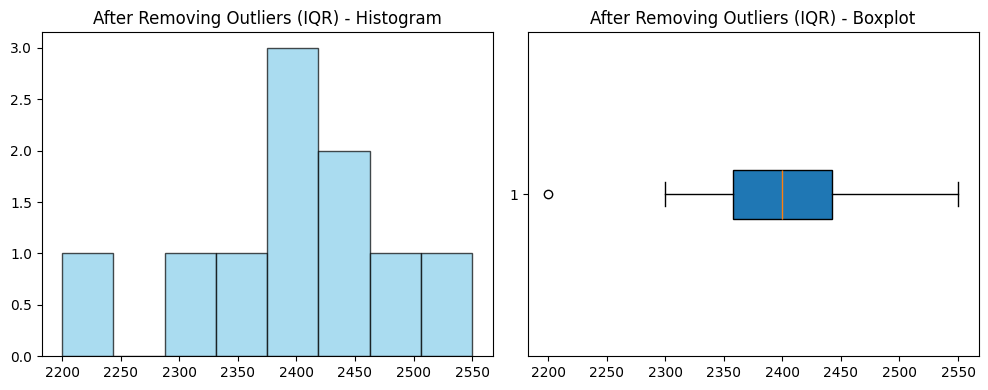

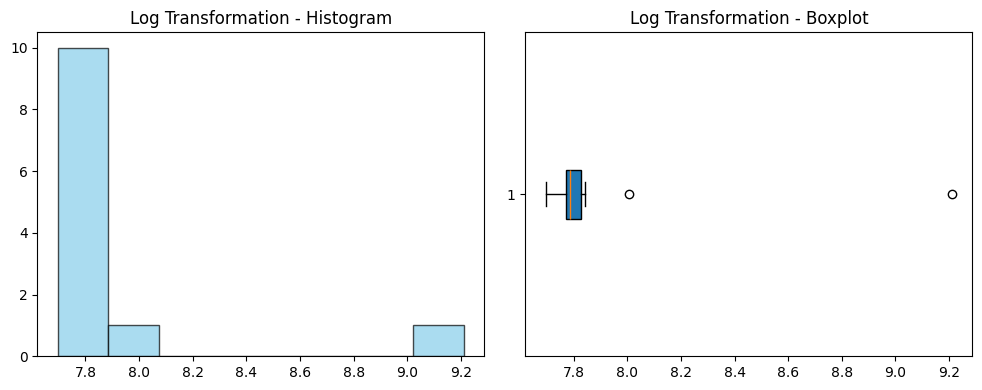

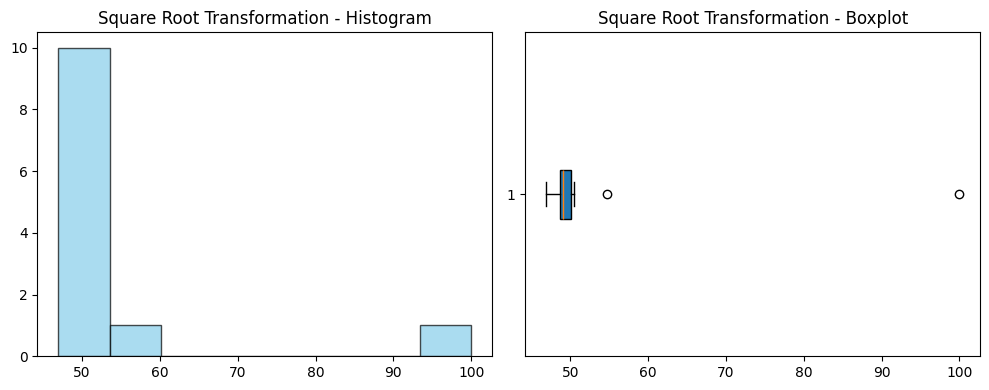

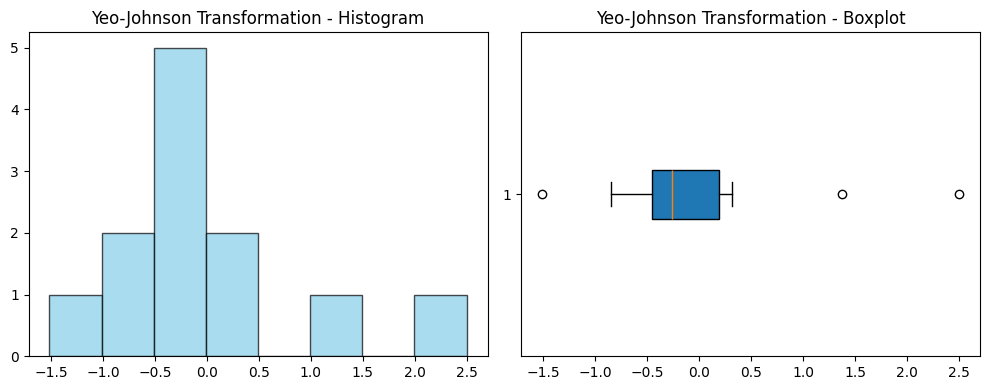

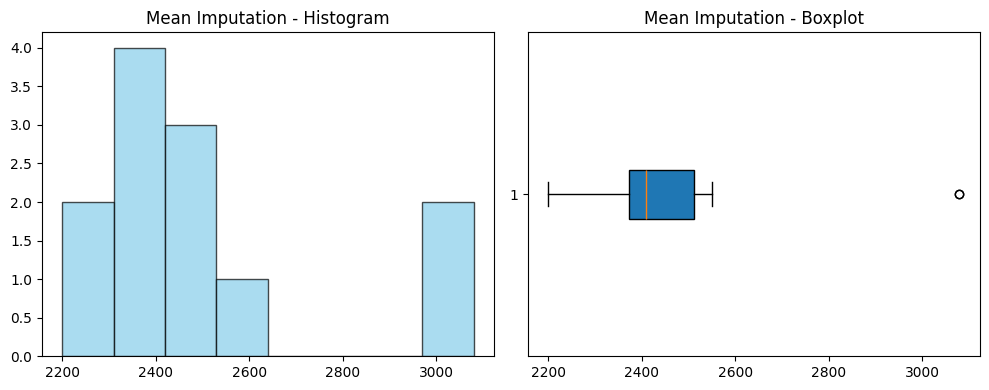

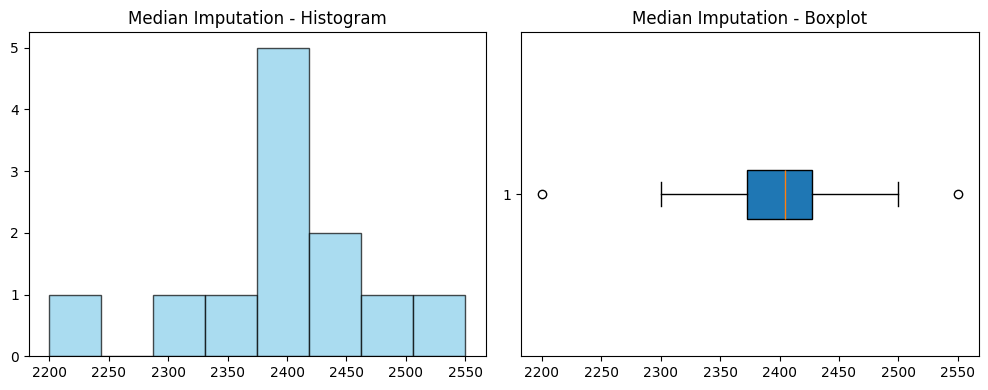

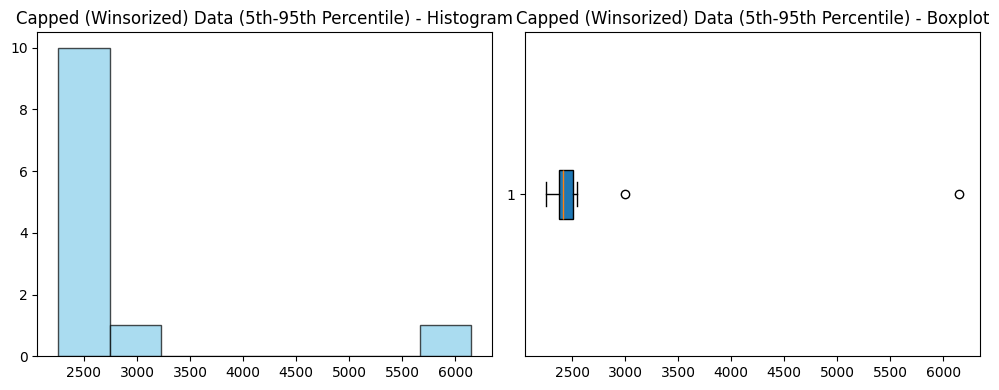

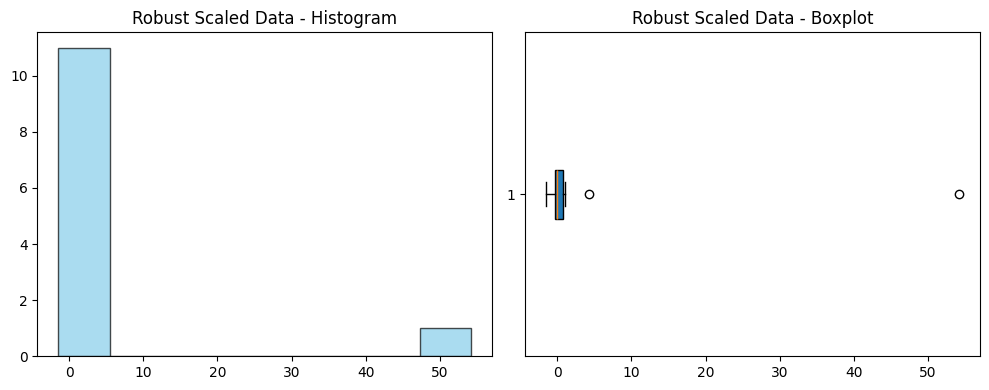


📊 Summary Table of Outlier Treatments:

    Original  Removed (IQR)  Imputed Mean  Imputed Median  Capped (5-95%)  \
0       2200         2200.0   2200.000000          2200.0          2255.0   
1       2500         2500.0   2500.000000          2500.0          2500.0   
2       2300         2300.0   2300.000000          2300.0          2300.0   
3       2400         2400.0   2400.000000          2400.0          2400.0   
4       2450         2450.0   2450.000000          2450.0          2450.0   
5       2550         2550.0   2550.000000          2550.0          2550.0   
6       2350         2350.0   2350.000000          2350.0          2350.0   
7       2400         2400.0   2400.000000          2400.0          2400.0   
8       2380         2380.0   2380.000000          2380.0          2380.0   
9       2420         2420.0   2420.000000          2420.0          2420.0   
10      3000            NaN   3079.166667          2410.0          3000.0   
11     10000            NaN   3079.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import PowerTransformer, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# -----------------------------
# 1️⃣ SAMPLE DATASET (WITH OUTLIERS)
data = np.array([2200, 2500, 2300, 2400, 2450, 2550, 2350, 2400, 2380, 2420, 3000, 10000])

# Helper function to plot histogram + boxplot side by side
def plot_hist_box(data, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].hist(data, bins=8, color="skyblue", edgecolor="black", alpha=0.7)
    axes[0].set_title(f"{title} - Histogram")
    axes[1].boxplot(data, vert=False, patch_artist=True)
    axes[1].set_title(f"{title} - Boxplot")
    plt.tight_layout()
    plt.show()

plot_hist_box(data, "Original Data (With Outliers)")

# -----------------------------
# 2️⃣ OUTLIER DETECTION METHODS

def detect_outliers_iqr(data):
    Q1, Q3 = np.percentile(data, [25, 75])
    IQR = Q3 - Q1
    lb, ub = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return data[(data < lb) | (data > ub)], lb, ub

def detect_outliers_zscore(data, threshold=3):
    z = np.abs(stats.zscore(data))
    return data[z > threshold]

def detect_outliers_modified_z(data, threshold=3.5):
    median = np.median(data)
    mad = np.median(np.abs(data - median))
    mod_z = 0.6745 * (data - median) / mad
    return data[np.abs(mod_z) > threshold]

iqr_outliers, lb_iqr, ub_iqr = detect_outliers_iqr(data)
z_outliers = detect_outliers_zscore(data)
mz_outliers = detect_outliers_modified_z(data)

print(f"📌 IQR Outliers: {iqr_outliers}")
print(f"📌 Z-Score Outliers: {z_outliers}")
print(f"📌 Modified Z-Score Outliers: {mz_outliers}")

# -----------------------------
# 3️⃣ OUTLIER REMOVAL (USING IQR)
cleaned_data = data[(data >= lb_iqr) & (data <= ub_iqr)]
plot_hist_box(cleaned_data, "After Removing Outliers (IQR)")

# -----------------------------
# 4️⃣ TRANSFORMATION METHODS
log_transformed = np.log1p(data)
sqrt_transformed = np.sqrt(data)
pt = PowerTransformer(method='yeo-johnson')
transformed_pt = pt.fit_transform(data.reshape(-1, 1)).flatten()

plot_hist_box(log_transformed, "Log Transformation")
plot_hist_box(sqrt_transformed, "Square Root Transformation")
plot_hist_box(transformed_pt, "Yeo-Johnson Transformation")

# -----------------------------
# 5️⃣ IMPUTATION METHODS
imputed_mean = np.where((data < lb_iqr) | (data > ub_iqr), np.mean(data), data)
imputed_median = np.where((data < lb_iqr) | (data > ub_iqr), np.median(data), data)

plot_hist_box(imputed_mean, "Mean Imputation")
plot_hist_box(imputed_median, "Median Imputation")

# -----------------------------
# 6️⃣ CAPPING / WINSORIZATION
capped_data = np.clip(data, np.percentile(data, 5), np.percentile(data, 95))
plot_hist_box(capped_data, "Capped (Winsorized) Data (5th-95th Percentile)")

# -----------------------------
# 7️⃣ ROBUST SCALING
scaler = RobustScaler()
scaled_data = scaler.fit_transform(data.reshape(-1, 1)).flatten()
plot_hist_box(scaled_data, "Robust Scaled Data")

# -----------------------------
# 8️⃣ COMPARISON TABLE
summary = pd.DataFrame({
    "Original": data,
    "Removed (IQR)": np.append(cleaned_data, [np.nan]*(len(data)-len(cleaned_data))),
    "Imputed Mean": imputed_mean,
    "Imputed Median": imputed_median,
    "Capped (5-95%)": capped_data,
    "Log Transform": np.round(log_transformed, 2),
    "Robust Scaled": np.round(scaled_data, 2)
})
print("\n📊 Summary Table of Outlier Treatments:\n")
print(summary)

# -----------------------------
# 9️⃣ BONUS: MODEL PERFORMANCE COMPARISON
# Let's assume 'data' is a feature, and create a simple target variable (linear + noise)
X = data.reshape(-1, 1)
y = 5 * data + np.random.normal(0, 1000, size=len(data))  # y = 5x + noise

model = LinearRegression()

# Model on original data
model.fit(X, y)
y_pred_orig = model.predict(X)
rmse_orig = np.sqrt(mean_squared_error(y, y_pred_orig))
r2_orig = r2_score(y, y_pred_orig)

# Model after removing outliers
X_clean = cleaned_data.reshape(-1, 1)
y_clean = y[(data >= lb_iqr) & (data <= ub_iqr)]
model.fit(X_clean, y_clean)
y_pred_clean = model.predict(X_clean)
rmse_clean = np.sqrt(mean_squared_error(y_clean, y_pred_clean))
r2_clean = r2_score(y_clean, y_pred_clean)

print("\n📈 Model Performance Comparison")
print(f"Original Data -> RMSE: {rmse_orig:.2f}, R²: {r2_orig:.3f}")
print(f"After Outlier Removal -> RMSE: {rmse_clean:.2f}, R²: {r2_clean:.3f}")


📌 Raw Data:
      Age    Salary Department Purchased
0   25.0    3000.0         IT       Yes
1   30.0    3500.0         HR        No
2   28.0    3400.0    Finance        No
3    NaN    3600.0         IT       Yes
4   35.0  100000.0    Finance       Yes
5   80.0    3200.0         HR        No
6   29.0    3300.0         HR       Yes
7   27.0    3100.0    Finance        No
8   26.0       NaN         IT       Yes
9  100.0   50000.0    Finance       Yes

🔧 Handling Missing Values...

✅ After Missing Value Imputation:
           Age    Salary Department Purchased
0   25.000000    3000.0         IT       Yes
1   30.000000    3500.0         HR        No
2   28.000000    3400.0    Finance        No
3   42.222222    3600.0         IT       Yes
4   35.000000  100000.0    Finance       Yes
5   80.000000    3200.0         HR        No
6   29.000000    3300.0         HR       Yes
7   27.000000    3100.0    Finance        No
8   26.000000    3400.0         IT       Yes
9  100.000000   50000.0    Fina

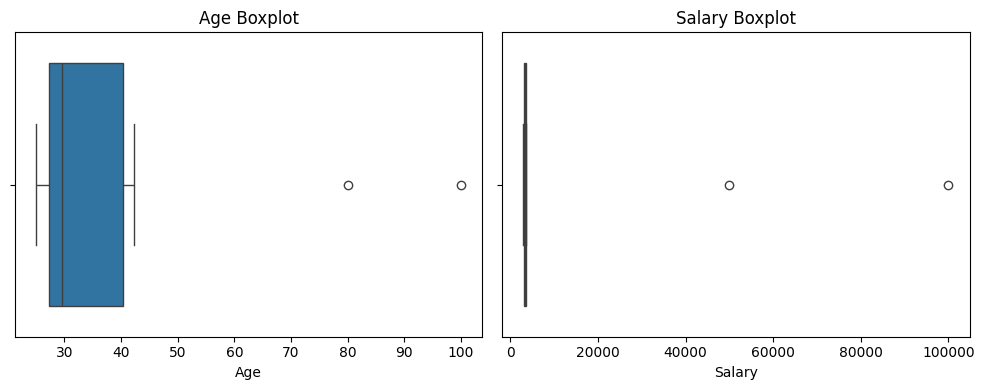


🔧 Encoding Categorical Variables...

✅ After Encoding:
          Age  Salary  Purchased  Department_HR  Department_IT
0  25.000000  3000.0          1          False           True
1  30.000000  3500.0          0           True          False
2  28.000000  3400.0          0          False          False
3  42.222222  3600.0          1          False           True
6  29.000000  3300.0          1           True          False
7  27.000000  3100.0          0          False          False
8  26.000000  3400.0          1          False           True

🔧 Feature Scaling...

✅ After Scaling:
          Age  Salary  Purchased  Department_HR  Department_IT   Age_std  \
0  25.000000  3000.0          1          False           True -0.854198   
1  30.000000  3500.0          0           True          False  0.073638   
2  28.000000  3400.0          0          False          False -0.297497   
3  42.222222  3600.0          1          False           True  2.341681   
6  29.000000  3300.0          1

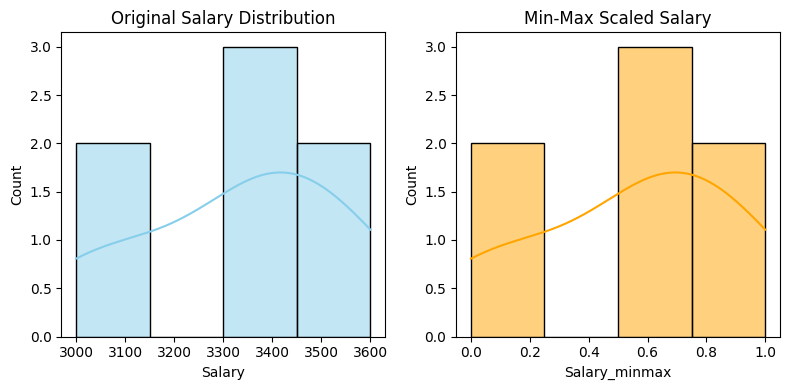

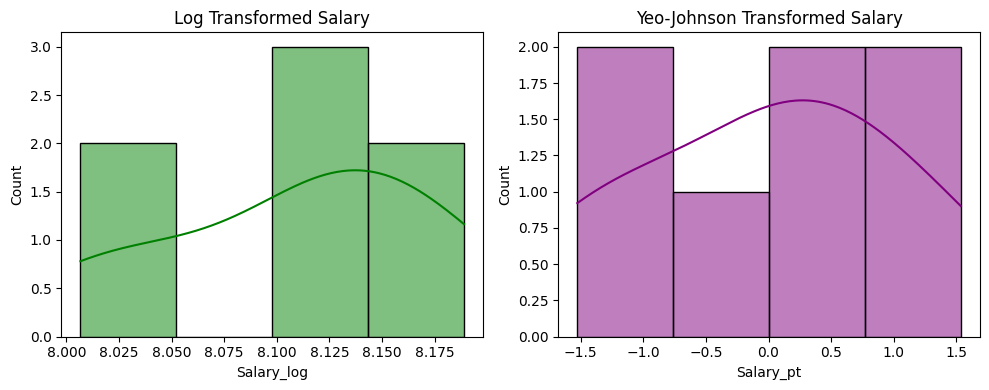


🔧 Feature Selection...

✅ After Feature Selection:
          Age  Salary  Purchased  Department_HR  Department_IT   Age_std  \
0  25.000000  3000.0          1          False           True -0.854198   
1  30.000000  3500.0          0           True          False  0.073638   
2  28.000000  3400.0          0          False          False -0.297497   
3  42.222222  3600.0          1          False           True  2.341681   
6  29.000000  3300.0          1           True          False -0.111929   
7  27.000000  3100.0          0          False          False -0.483064   
8  26.000000  3400.0          1          False           True -0.668631   

   Salary_minmax  Salary_robust  Salary_pt  
0       0.000000           -1.6  -1.527285  
1       0.833333            0.4   0.868493  
2       0.666667            0.0   0.270832  
3       1.000000            0.8   1.536163  
6       0.500000           -0.4  -0.262421  
7       0.166667           -1.2  -1.156615  
8       0.666667            0.0

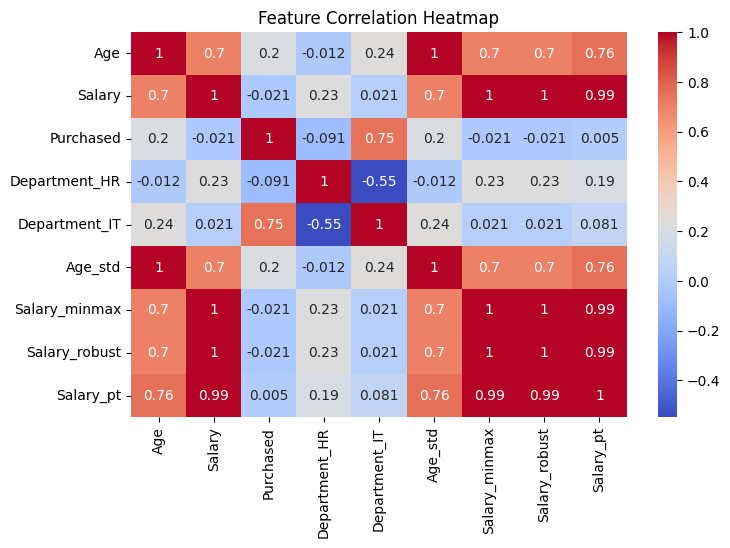

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler,
    OneHotEncoder, LabelEncoder, PowerTransformer
)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split

# -----------------------------
# 1️⃣ CREATE SAMPLE DATA
df = pd.DataFrame({
    "Age": [25, 30, 28, np.nan, 35, 80, 29, 27, 26, 100],
    "Salary": [3000, 3500, 3400, 3600, 100000, 3200, 3300, 3100, np.nan, 50000],
    "Department": ["IT", "HR", "Finance", "IT", "Finance", "HR", "HR", "Finance", "IT", "Finance"],
    "Purchased": ["Yes", "No", "No", "Yes", "Yes", "No", "Yes", "No", "Yes", "Yes"]
})

print("📌 Raw Data:\n", df)

# -----------------------------
# 2️⃣ HANDLE MISSING VALUES
print("\n🔧 Handling Missing Values...")

imputer_mean = SimpleImputer(strategy="mean")
df["Age"] = imputer_mean.fit_transform(df[["Age"]])

imputer_median = SimpleImputer(strategy="median")
df["Salary"] = imputer_median.fit_transform(df[["Salary"]])

print("\n✅ After Missing Value Imputation:\n", df)

# -----------------------------
# 3️⃣ OUTLIER DETECTION + REMOVAL (IQR)
def detect_outliers_iqr(col):
    Q1, Q3 = np.percentile(col, [25, 75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return (col < lower) | (col > upper)

outliers_age = detect_outliers_iqr(df["Age"])
outliers_salary = detect_outliers_iqr(df["Salary"])

print("\n🚨 Outliers in Age:", df["Age"][outliers_age].values)
print("🚨 Outliers in Salary:", df["Salary"][outliers_salary].values)

# Option: Remove Outliers
df_clean = df[~outliers_age & ~outliers_salary].copy()
print("\n✅ After Removing Outliers:\n", df_clean)

# Visualize Boxplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=df["Age"], ax=axes[0])
axes[0].set_title("Age Boxplot")
sns.boxplot(x=df["Salary"], ax=axes[1])
axes[1].set_title("Salary Boxplot")
plt.tight_layout()
plt.show()

# -----------------------------
# 4️⃣ ENCODING CATEGORICAL DATA
print("\n🔧 Encoding Categorical Variables...")

# One-Hot Encoding (for ML models that can't handle text)
df_encoded = pd.get_dummies(df_clean, columns=["Department"], drop_first=True)

# Label Encoding (for binary categorical)
le = LabelEncoder()
df_encoded["Purchased"] = le.fit_transform(df_encoded["Purchased"])

print("\n✅ After Encoding:\n", df_encoded)

# -----------------------------
# 5️⃣ FEATURE SCALING
print("\n🔧 Feature Scaling...")

scaler_standard = StandardScaler()
df_encoded["Age_std"] = scaler_standard.fit_transform(df_encoded[["Age"]])

scaler_minmax = MinMaxScaler()
df_encoded["Salary_minmax"] = scaler_minmax.fit_transform(df_encoded[["Salary"]])

scaler_robust = RobustScaler()
df_encoded["Salary_robust"] = scaler_robust.fit_transform(df_encoded[["Salary"]])

print("\n✅ After Scaling:\n", df_encoded)

# Visualize Scaling
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_encoded["Salary"], kde=True, color="skyblue")
plt.title("Original Salary Distribution")
plt.subplot(1, 2, 2)
sns.histplot(df_encoded["Salary_minmax"], kde=True, color="orange")
plt.title("Min-Max Scaled Salary")
plt.tight_layout()
plt.show()

# -----------------------------
# 6️⃣ FEATURE TRANSFORMATION (LOG & POWER)
df_encoded["Salary_log"] = np.log1p(df_encoded["Salary"])
pt = PowerTransformer(method='yeo-johnson')
df_encoded["Salary_pt"] = pt.fit_transform(df_encoded[["Salary"]])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_encoded["Salary_log"], kde=True, color="green")
plt.title("Log Transformed Salary")
plt.subplot(1, 2, 2)
sns.histplot(df_encoded["Salary_pt"], kde=True, color="purple")
plt.title("Yeo-Johnson Transformed Salary")
plt.tight_layout()
plt.show()

# -----------------------------
# 7️⃣ FEATURE SELECTION (Variance Threshold)
print("\n🔧 Feature Selection...")
selector = VarianceThreshold(threshold=0.01)
df_selected = df_encoded[df_encoded.columns[selector.fit(df_encoded).get_support(indices=True)]]

print("\n✅ After Feature Selection:\n", df_selected)

# -----------------------------
# 8️⃣ CORRELATION HEATMAP
plt.figure(figsize=(8, 5))
sns.heatmap(df_selected.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()
